# Support Vector Machines — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 5**

This notebook follows the R lecture `lectures/week5/svm.Rmd` section by section, replacing `e1071::svm` with scikit-learn's `SVC` and `caret::train` with `GridSearchCV`.

| R (`e1071`) | scikit-learn `SVC` |
|---|---|
| `kernel = "linear"`, `"polynomial"`, `"radial"` | `kernel="linear"`, `"poly"`, `"rbf"` |
| `cost` | `C` |
| `gamma` (radial) | `gamma` |
| `fit$index` (support vectors) | `svc.support_` |
| `decision.values = TRUE` | `svc.decision_function()` |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC

LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

## Simulated data
Two slightly separated classes in two dimensions: the same points as the R slides (simulated in R and saved to `svm_sim.csv`).

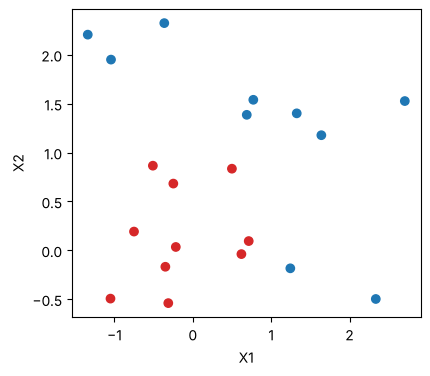

In [2]:
sim = pd.read_csv(DATA + "svm_sim.csv")
x, y = sim[["X1", "X2"]].to_numpy(), sim["y"].to_numpy()
plt.figure(figsize=(4.5, 4))
plt.scatter(x[:, 0], x[:, 1], c=np.where(y == 1, "tab:blue", "tab:red"))
plt.xlabel("X1"); plt.ylabel("X2"); plt.show()

## Linear SVM
Like the R example we don't scale here, because both features are on the same scale. Usually you **should** scale (a `StandardScaler` in a `Pipeline`).

In [3]:
svc = SVC(kernel="linear", C=10).fit(x, y)
print("support vectors:", len(svc.support_))

support vectors: 6


## Plotting the decision boundary and margins
For a linear kernel, `coef_` and `intercept_` give $\beta$ and $\beta_0$ directly (no need to rebuild them from the support vectors as in R). The boundary is where the decision function is 0; the margins are where it is $\pm 1$.

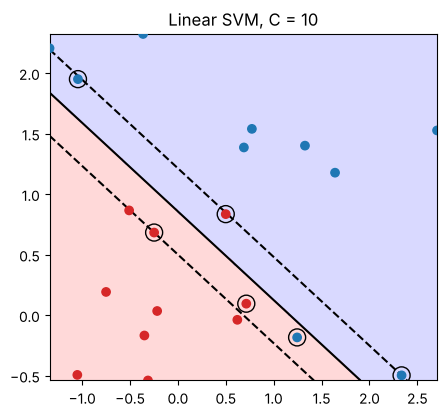

beta: [[2.056 2.806]]  beta0: [-2.404]


In [4]:
def plot_svm(model, x, y, ax, title=""):
    g1, g2 = np.meshgrid(np.linspace(x[:, 0].min(), x[:, 0].max(), 200),
                         np.linspace(x[:, 1].min(), x[:, 1].max(), 200))
    grid = np.c_[g1.ravel(), g2.ravel()]
    z = model.decision_function(grid).reshape(g1.shape)
    ax.contourf(g1, g2, z > 0, alpha=0.15, colors=["red", "blue"])
    ax.contour(g1, g2, z, levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")
    ax.scatter(x[:, 0], x[:, 1], c=np.where(y == 1, "tab:blue", "tab:red"), zorder=3)
    sv = x[model.support_]
    ax.scatter(sv[:, 0], sv[:, 1], s=150, facecolors="none", edgecolors="k", zorder=4)
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(5, 4.5))
plot_svm(svc, x, y, ax, "Linear SVM, C = 10")
plt.show()
print("beta:", svc.coef_.round(3), " beta0:", svc.intercept_.round(3))

## The cost C changes the margin
Small C: wide margin, many support vectors (more bias, less variance). Large C: narrow margin, few support vectors.

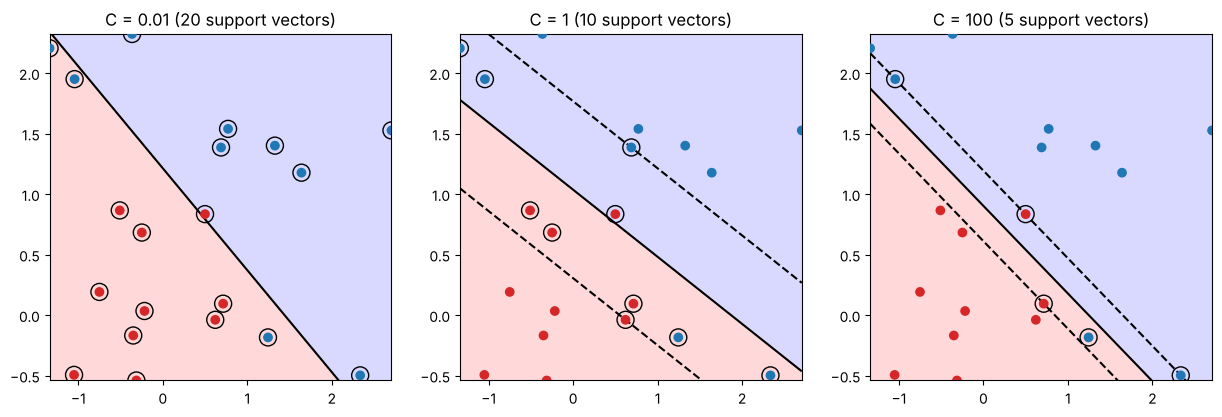

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, cc in zip(axes, [0.01, 1, 100]):
    m = SVC(kernel="linear", C=cc).fit(x, y)
    plot_svm(m, x, y, ax, f"C = {cc} ({len(m.support_)} support vectors)")
plt.show()

## Polynomial kernel
`e1071` defaults to degree 3, `gamma = 1/p`, and `coef0 = 0` for the polynomial kernel; we match those settings.

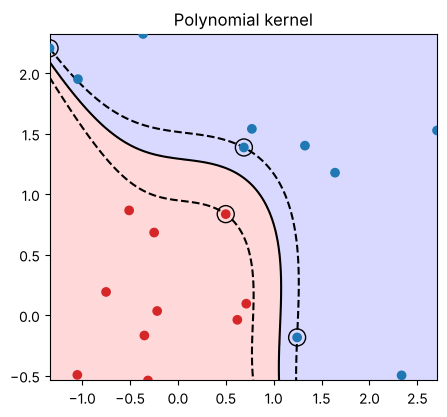

In [6]:
svc_poly = SVC(kernel="poly", degree=3, gamma=1 / 2, coef0=0, C=10).fit(x, y)
fig, ax = plt.subplots(figsize=(5, 4.5))
plot_svm(svc_poly, x, y, ax, "Polynomial kernel")
plt.show()

## Radial kernel: the ESL mixture data
From *The Elements of Statistical Learning*: no clean separation, and the boundary must be non-linear. `e1071`'s default radial `gamma` is `1/p` = 0.5.

support vectors: 103


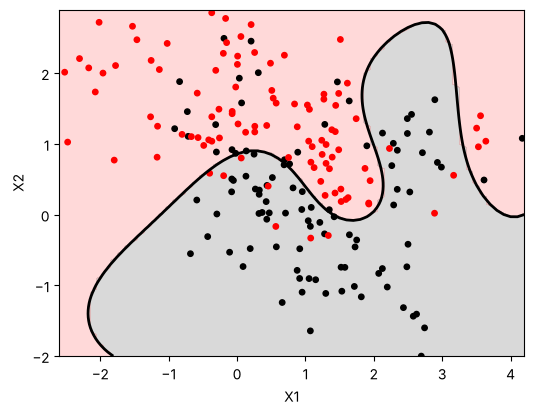

In [7]:
esl = pd.read_csv(DATA + "esl_mixture.csv")
grid = pd.read_csv(DATA + "esl_mixture_grid.csv")
px1, px2 = grid["px1"].dropna().to_numpy(), grid["px2"].to_numpy()
X_esl, y_esl = esl[["X1", "X2"]].to_numpy(), esl["y"].to_numpy()

svc_rbf = SVC(kernel="rbf", gamma=0.5, C=5).fit(X_esl, y_esl)
print("support vectors:", len(svc_rbf.support_))

g1, g2 = np.meshgrid(px1, px2)
z = svc_rbf.decision_function(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
plt.figure(figsize=(6, 4.5))
plt.contourf(g1, g2, z > 0, alpha=0.15, colors=["black", "red"])
plt.contour(g1, g2, z, levels=[0], colors="k", linewidths=2)
plt.scatter(X_esl[:, 0], X_esl[:, 1], c=np.where(y_esl == 1, "red", "black"), s=15)
plt.xlabel("X1"); plt.ylabel("X2"); plt.show()

## Application: TB gene expression biomarkers
The TB NanoString data: 179 people (active TB vs. latent infection), 107 genes. Tune a linear SVM (C) and a radial SVM (C and gamma) by 10-fold CV on AUC, with scaling inside the pipeline, then evaluate on a held-out test set.

In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix

tb = pd.read_csv(DATA + "TBnanostring.csv")
X_tb = tb.drop(columns="TB_Status"); y_tb = (tb["TB_Status"] == "TB").astype(int)
Xtr, Xte, ytr, yte = train_test_split(X_tb, y_tb, test_size=0.3, stratify=y_tb, random_state=1)
cv = StratifiedKFold(10, shuffle=True, random_state=1)

lin = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="linear")),
                   {"svc__C": [0.001, 0.01, 0.1, 1, 10]}, cv=cv, scoring="roc_auc").fit(Xtr, ytr)
rad = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")),
                   {"svc__C": [0.25, 0.5, 1, 2, 4, 8, 16, 32],
                    "svc__gamma": [0.001, 0.003, 0.01, 0.03]},
                   cv=cv, scoring="roc_auc").fit(Xtr, ytr)

print(pd.DataFrame(lin.cv_results_)[["param_svc__C", "mean_test_score"]].round(3))
print("radial best:", rad.best_params_, "| CV AUC:", round(rad.best_score_, 3))

   param_svc__C  mean_test_score
0         0.001            0.937
1         0.010            0.929
2         0.100            0.928
3         1.000            0.913
4        10.000            0.913
radial best: {'svc__C': 1, 'svc__gamma': 0.03} | CV AUC: 0.95


As in R, the smallest costs (widest margins) do best for the linear SVM: strong regularization helps with 107 genes and 125 training samples.

## Test-set performance
`roc_auc_score` only needs a ranking, so we can use the SVM's decision values directly. (In R, `classProbs = TRUE` fits Platt scaling to get probabilities; in scikit-learn that's `SVC(probability=True)`.)

In [9]:
def test_perf(model):
    pred = model.predict(Xte)
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    return {"AUC": roc_auc_score(yte, model.decision_function(Xte)),
            "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp)}

pd.DataFrame({"linear": test_perf(lin), "radial": test_perf(rad)}).T.round(3)

,AUC,Sensitivity,Specificity
linear,0.947,0.750,1.0
radial,0.921,0.792,1.0


Both kernels reach a test AUC of roughly 0.92-0.95, similar to kNN and the 3-gene score from earlier weeks. (The split and CV folds differ from R, so the numbers differ a little from the slides.)

## Session info

In [10]:
import sys, sklearn, matplotlib
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2
